In [ ]:
# Import Library
import pandas as pd # data analysis
import numpy as np # mathematical operations
import matplotlib.pyplot as plt # visualization
import seaborn as sns # visualization

In [ ]:
from google.colab import files
uploaded=files.upload()
csv_file=next(iter(uploaded))
df=pd.read_csv(csv_file)

Saving car dataset.zip to car dataset.zip


In [ ]:
df.head()

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [ ]:
df.tail()

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
7248,7248,Volkswagen Vento Diesel Trendline,Hyderabad,2011,89411,Diesel,Manual,First,20.54 kmpl,1598 CC,103.6 bhp,5.0,NaN,NaN
7249,7249,Volkswagen Polo GT TSI,Mumbai,2015,59000,Petrol,Automatic,First,17.21 kmpl,1197 CC,103.6 bhp,5.0,NaN,NaN
7250,7250,Nissan Micra Diesel XV,Kolkata,2012,28000,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,NaN,NaN
7251,7251,Volkswagen Polo GT TSI,Pune,2013,52262,Petrol,Automatic,Third,17.2 kmpl,1197 CC,103.6 bhp,5.0,NaN,NaN
7252,7252,Mercedes-Benz E-Class 2009-2013 E 220 CDI Avan...,Kochi,2014,72443,Diesel,Automatic,First,10.0 kmpl,2148 CC,170 bhp,5.0,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No.              7253 non-null   int64  
 1   Name               7253 non-null   object 
 2   Location           7253 non-null   object 
 3   Year               7253 non-null   int64  
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   object 
 6   Transmission       7253 non-null   object 
 7   Owner_Type         7253 non-null   object 
 8   Mileage            7251 non-null   object 
 9   Engine             7207 non-null   object 
 10  Power              7207 non-null   object 
 11  Seats              7200 non-null   float64
 12  New_Price          1006 non-null   object 
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), object(9)
memory usage: 793.4+ KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
S.No.,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,2
Engine,46


In [ ]:
from pandas.core.arrays import categorical
# Missing value treatment

#if the column is numerical/ categorical

#Numerical - Median, categorical - Mode

In [ ]:
df = df.fillna(df.mode().iloc[0])

In [ ]:
#numericals missing value treatment
num = df.select_dtypes(include = 'number').columns
df[num]=df[num].fillna(df[num].median())

In [ ]:
df.isnull().sum()

,0
S.No.,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,0
Engine,0


In [ ]:
cat = df.select_dtypes(include = 'object').columns
df[cat]=df[cat].fillna(df[cat].mode())

In [ ]:
# Outliers
df.select_dtypes(include = ['int64','float64']).columns

Index(['S.No.', 'Year', 'Kilometers_Driven', 'Seats', 'Price'], dtype='object')

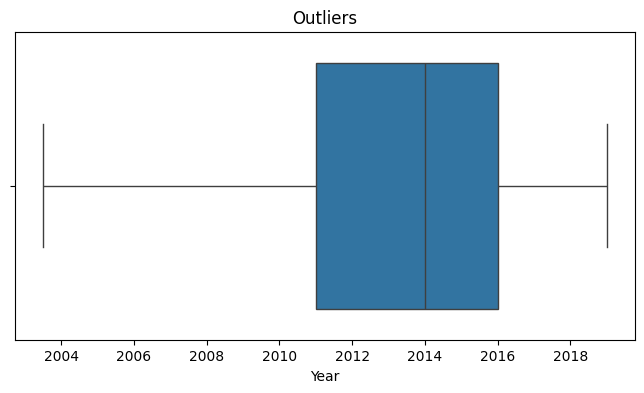

In [ ]:
# Outlier check
plt.figure(figsize=(8,4))
sns.boxplot(x= df['Year'])
plt.title("Outliers")
plt.show()

In [ ]:
Q1 = df['Year'].quantile(0.25)
Q3 = df['Year'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR



In [ ]:
df['Year'] = df['Year'].clip(lower_bound,upper_bound)


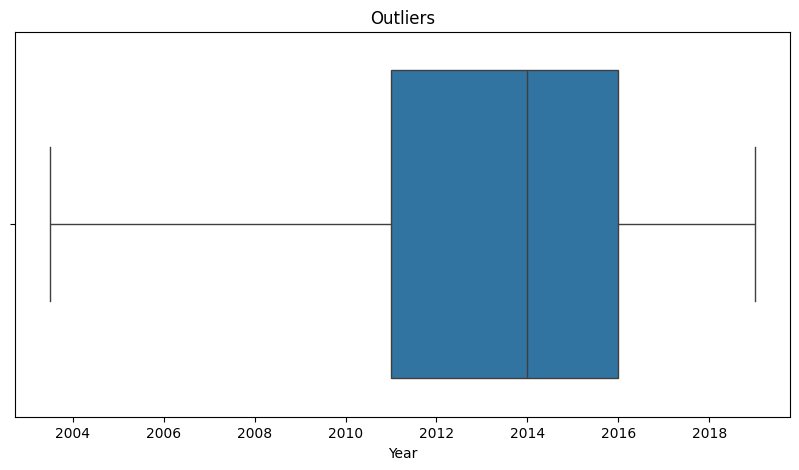

In [ ]:
# Outlier check
plt.figure(figsize=(10,5))
sns.boxplot(x= df['Year'])
plt.title("Outliers")
plt.show()

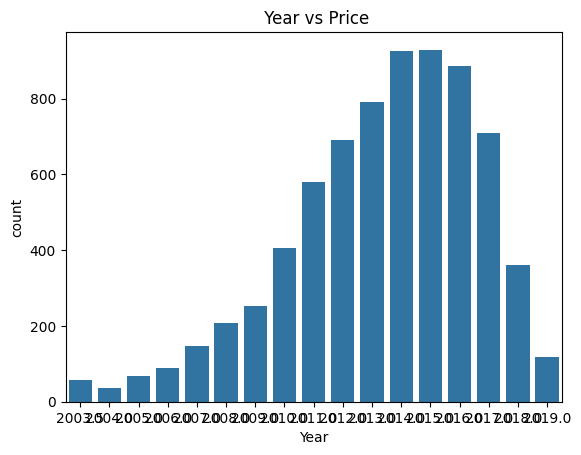

In [ ]:
# Univariate analysis
sns.countplot(x = df['Year'])
plt.title(" Year vs Price")
plt.show()

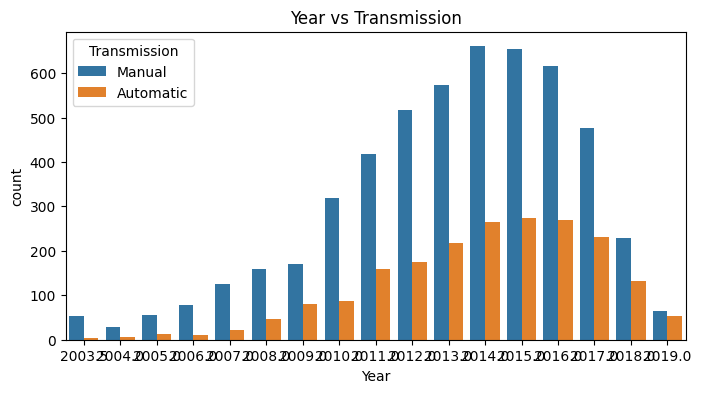

In [ ]:
# Bivariate analysis
plt.figure(figsize=(8,4))
sns.countplot(x= df['Year'] , hue=df['Transmission'])
plt.title("Year vs Transmission")
plt.show()

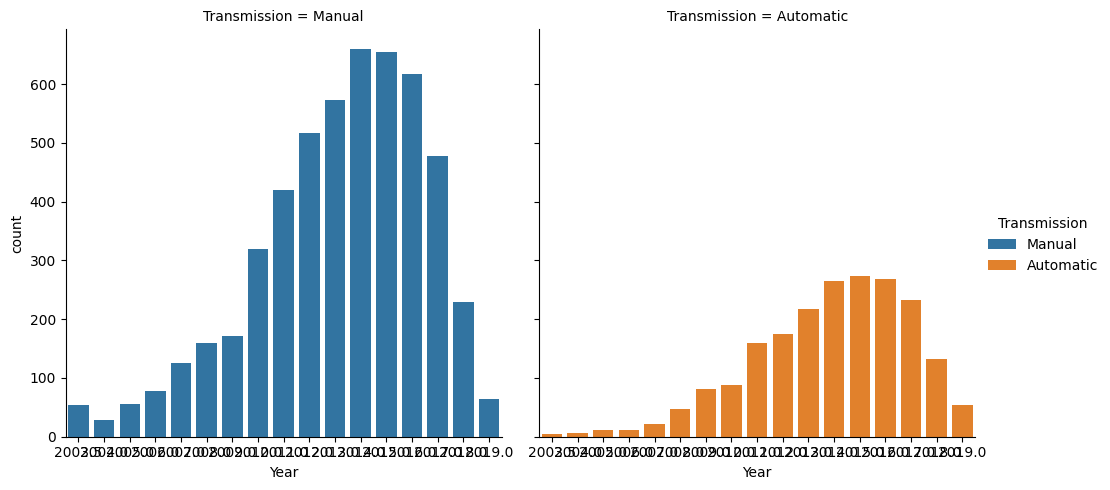

In [ ]:
# multivariate

sns.catplot(x= 'Year', hue = 'Transmission',col = 'Transmission',data = df, kind = 'count')
plt.show()

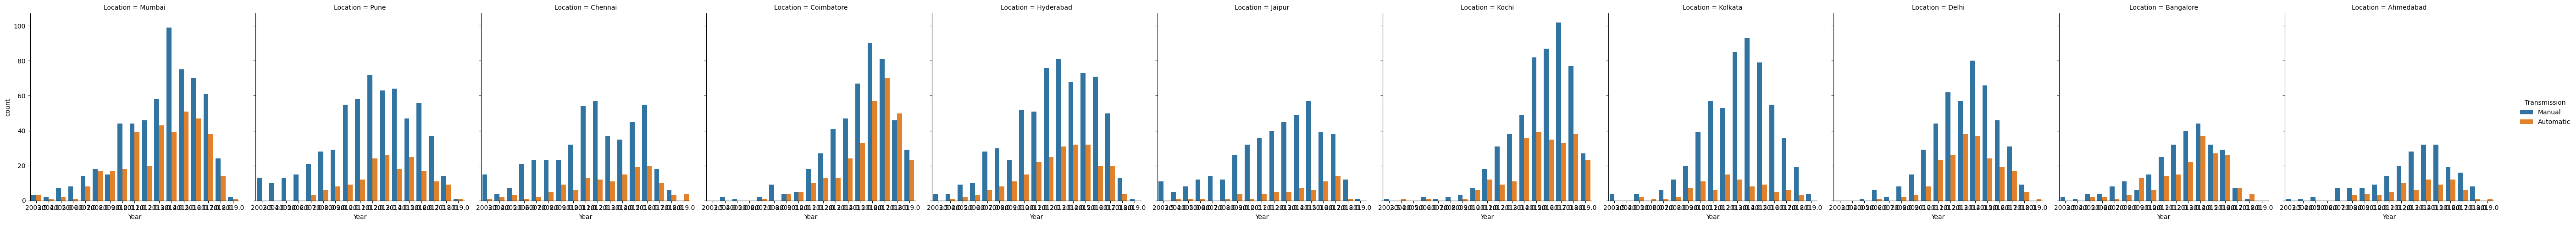

In [ ]:
sns.catplot(x = 'Year',hue = 'Transmission', col =  'Location', data = df, kind = 'count')
plt.show()

In [ ]:
# converting objective data to numerical
df1= df.select_dtypes(include = 'object').columns
df1

Index(['Name', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type',
       'Mileage', 'Engine', 'Power', 'New_Price'],
      dtype='object')

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in df1:
  df[col] = le.fit_transform(df[col])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No.              7253 non-null   int64  
 1   Name               7253 non-null   int64  
 2   Location           7253 non-null   int64  
 3   Year               7253 non-null   float64
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   int64  
 6   Transmission       7253 non-null   int64  
 7   Owner_Type         7253 non-null   int64  
 8   Mileage            7253 non-null   int64  
 9   Engine             7253 non-null   int64  
 10  Power              7253 non-null   int64  
 11  Seats              7253 non-null   float64
 12  New_Price          7253 non-null   int64  
 13  Price              7253 non-null   float64
dtypes: float64(3), int64(11)
memory usage: 793.4 KB
